# Refund Assistant — the full LangGraph example from the talk

No real LLM or payment API is called — every node is a plain Python function with fake logic, so the graph
mechanics (state, nodes, edges, memory, pausing for a human) are easy to see. Swap in a real model or API call
later; the graph shape stays the same.

## 1. Define the State

The shared notebook every node reads and writes.

In [1]:
from typing import TypedDict, Optional
from langgraph.graph import StateGraph, START, END


class RefundState(TypedDict):
    order_id: str
    amount: float
    reason: str
    approved: Optional[bool]
    reply: Optional[str]

## 2. Write the Nodes

One plain Python function per job. Each one receives the state and returns only the fields it changed.

In [2]:
def classify(state: RefundState):
    print(f"[classify] Reading the request for order {state['order_id']}")
    # In a real agent, an LLM call would read the customer's message
    # and fill in order_id, amount, reason from free text.
    return {}


def check_order(state: RefundState):
    print(f"[check_order] Looking up order {state['order_id']} (amount: {state['amount']})")
    # In a real agent, this would call your order system / database.
    return {}


def issue_refund(state: RefundState):
    print(f"[issue_refund] Refunding {state['amount']} for order {state['order_id']}")
    # In a real agent, this would call your payments API.
    return {}


def send_reply(state: RefundState):
    if state.get("approved") is False:
        reply = f"Sorry, the refund for order {state['order_id']} was not approved."
    else:
        reply = f"Your refund of {state['amount']} for order {state['order_id']} is on its way."
    print(f"[send_reply] {reply}")
    return {"reply": reply}

### The decision node: route()

This is the diamond in the diagram. It is a small function that reads the state and returns the **name**
of the next node — not a node itself.

In [3]:
REFUND_LIMIT = 5000


def route(state: RefundState):
    if state["amount"] > REFUND_LIMIT:
        print(f"[route] {state['amount']} is over {REFUND_LIMIT} -> needs manager approval")
        return "manager_approval"
    print(f"[route] {state['amount']} is within limit -> straight to refund")
    return "issue_refund"

### The human-in-the-loop node: manager_approval()

`interrupt()` pauses the graph right here and hands a question out to whoever is running it. The state is
checkpointed, so the wait can last as long as it needs to — the run picks back up from this exact point.

In [4]:
from langgraph.types import interrupt


def manager_approval(state: RefundState):
    decision = interrupt(
        {
            "question": "Approve this refund?",
            "order_id": state["order_id"],
            "amount": state["amount"],
            "reason": state["reason"],
        }
    )
    print(f"[manager_approval] Manager said: {decision}")
    return {"approved": decision == "yes"}

## 3. Connect the Edges

- `add_node` registers each function as a node.
- `add_edge` is a fixed arrow: always go from A to B.
- `add_conditional_edges` calls `route()` after `check_order` and follows whichever node name it returns.
- Both `issue_refund` and the `approved` branch of `manager_approval` lead to `send_reply`.
- The `rejected` branch of `manager_approval` skips straight to `send_reply` too (no refund to issue).

In [5]:
builder = StateGraph(RefundState)

builder.add_node("classify", classify)
builder.add_node("check_order", check_order)
builder.add_node("manager_approval", manager_approval)
builder.add_node("issue_refund", issue_refund)
builder.add_node("send_reply", send_reply)

builder.add_edge(START, "classify")
builder.add_edge("classify", "check_order")

builder.add_conditional_edges("check_order", route)


def after_approval(state: RefundState):
    return "issue_refund" if state.get("approved") else "send_reply"


builder.add_conditional_edges("manager_approval", after_approval)

builder.add_edge("issue_refund", "send_reply")
builder.add_edge("send_reply", END)

## 4. Compile with memory

A checkpointer saves the state after every step. That is what makes the pause-and-resume in Part 6 possible,
and it is also what gives the graph memory across calls on the same `thread_id`.

`InMemorySaver` is for demos only — it is lost when the process ends. In production, swap it for the
SQLite or Postgres checkpointer so the memory survives a restart.

In [6]:
from langgraph.checkpoint.memory import InMemorySaver

graph = builder.compile(checkpointer=InMemorySaver())

## 5. Print / show the graph

A few ways to look at the compiled graph, from simplest to nicest.

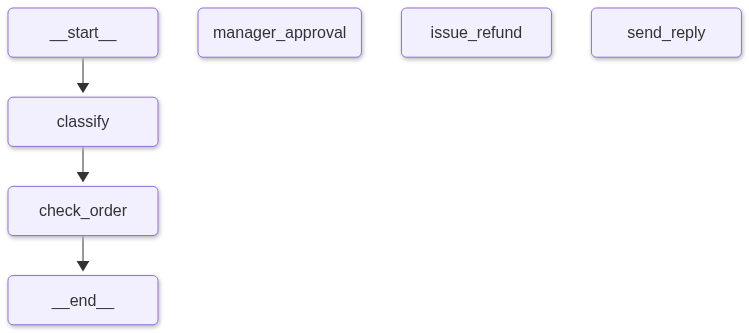

In [7]:
# Rendered image, inline in the notebook.
# Needs internet on first call (uses the Mermaid.ink API).
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

## 6. Run it — Path A: small refund (no approval needed)

800 is under the 5000 limit, so `route()` sends this straight to `issue_refund`. The graph runs start to
finish in one call.

In [8]:
config_a = {"configurable": {"thread_id": "order-1001"}}

result_a = graph.invoke(
    {"order_id": "1001", "amount": 800, "reason": "item arrived damaged"},
    config_a,
)
print("\nFinal state:", result_a)

[classify] Reading the request for order 1001
[check_order] Looking up order 1001 (amount: 800)
[route] 800 is within limit -> straight to refund
[issue_refund] Refunding 800 for order 1001
[send_reply] Your refund of 800 for order 1001 is on its way.

Final state: {'order_id': '1001', 'amount': 800, 'reason': 'item arrived damaged', 'reply': 'Your refund of 800 for order 1001 is on its way.'}


## 7. Run it — Path B: big refund (pauses for a manager)

8000 is over the 5000 limit, so `route()` sends this to `manager_approval`, which calls `interrupt()`.
The first `invoke()` call stops right there and returns — it does **not** raise an exception, it just pauses.

In [9]:
config_b = {"configurable": {"thread_id": "order-2002"}}

result_b = graph.invoke(
    {"order_id": "2002", "amount": 8000, "reason": "never arrived"},
    config_b,
)
print("\nPaused. Here is what the graph is asking:")
print(result_b["__interrupt__"])

[classify] Reading the request for order 2002
[check_order] Looking up order 2002 (amount: 8000)
[route] 8000 is over 5000 -> needs manager approval

Paused. Here is what the graph is asking:
[Interrupt(value={'question': 'Approve this refund?', 'order_id': '2002', 'amount': 8000, 'reason': 'never arrived'}, id='d68796da1a3f1d4f6c88329ebaca7a66')]


### Resume it — the manager says yes

This could run minutes, hours, or days later, even in a different process — the state was checkpointed
under `thread_id` "order-2002". `Command(resume=...)` sends the answer back into the same `interrupt()` call.

In [32]:
from langgraph.types import Command

result_b_done = graph.invoke(Command(resume="yes"), config_b)
print("\nFinal state:", result_b_done)

[manager_approval] Manager said: yes
[issue_refund] Refunding 8000 for order 2002
[send_reply] Your refund of 8000 for order 2002 is on its way.

Final state: {'order_id': '2002', 'amount': 8000, 'reason': 'never arrived', 'approved': True, 'reply': 'Your refund of 8000 for order 2002 is on its way.'}


### Or: the manager says no

Run this on a **fresh thread_id** to see the rejection path instead (don't reuse `order-2002`, which is
already finished above).

In [33]:
config_c = {"configurable": {"thread_id": "order-3003"}}

result_c = graph.invoke(
    {"order_id": "3003", "amount": 9500, "reason": "changed my mind"},
    config_c,
)
print("Paused:", result_c["__interrupt__"])

result_c_done = graph.invoke(Command(resume="no"), config_c)
print("\nFinal state:", result_c_done)

[classify] Reading the request for order 3003
[check_order] Looking up order 3003 (amount: 9500)
[route] 9500 is over 5000 -> needs manager approval
Paused: [Interrupt(value={'question': 'Approve this refund?', 'order_id': '3003', 'amount': 9500, 'reason': 'changed my mind'}, id='186a4fe4abdb09dbecb6f714a34415a6')]
[manager_approval] Manager said: no
[send_reply] Sorry, the refund for order 3003 was not approved.

Final state: {'order_id': '3003', 'amount': 9500, 'reason': 'changed my mind', 'approved': False, 'reply': 'Sorry, the refund for order 3003 was not approved.'}


## 8. Peek at the saved checkpoints (optional)

Because `InMemorySaver` kept every step, you can look at the full history for one thread — useful for
debugging, and the same idea LangSmith tracing builds on.

In [34]:
for checkpoint in graph.get_state_history(config_b):
    print(checkpoint.values, "->", checkpoint.next)

{'order_id': '2002', 'amount': 8000, 'reason': 'never arrived', 'approved': True, 'reply': 'Your refund of 8000 for order 2002 is on its way.'} -> ()
{'order_id': '2002', 'amount': 8000, 'reason': 'never arrived', 'approved': True} -> ('send_reply',)
{'order_id': '2002', 'amount': 8000, 'reason': 'never arrived', 'approved': True} -> ('issue_refund',)
{'order_id': '2002', 'amount': 8000, 'reason': 'never arrived'} -> ('manager_approval',)
{'order_id': '2002', 'amount': 8000, 'reason': 'never arrived'} -> ('check_order',)
{'order_id': '2002', 'amount': 8000, 'reason': 'never arrived'} -> ('classify',)
{} -> ('__start__',)
